# 10 — Hot vs Reference Day Comparison

This notebook compares intra-Sevilla mobility patterns between selected hot days and matched reference days.

The purpose at this stage is descriptive:

- compare total and hourly mobility;
- identify differences during thermally relevant daytime hours;
- prepare district-level mobility indicators for later comparison with heat-conditioned accessibility.

This notebook does not yet interpret observed mobility differences as causal effects of heat.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

MOBILE_INTERIM = (
    PROJECT_ROOT
    / "data"
    / "mobile"
    / "interim"
)

MOBILE_PROCESSED = (
    PROJECT_ROOT
    / "data"
    / "mobile"
    / "processed"
)

MOBILE_PROCESSED.mkdir(
    parents=True,
    exist_ok=True
)

OD_FILE = (
    MOBILE_INTERIM
    / "sevilla_od_heat_reference_sample.parquet"
)

ZONE_FILE = (
    MOBILE_INTERIM
    / "sevilla_districts_v2.gpkg"
)

print("OD file exists:", OD_FILE.exists())
print("Zone file exists:", ZONE_FILE.exists())

OD file exists: True
Zone file exists: True


In [2]:
od = pd.read_parquet(OD_FILE)
zones = gpd.read_file(ZONE_FILE)

print("OD rows:", f"{len(od):,}")
print("Zones:", len(zones))

print("\nDates:")
print(
    pd.to_datetime(od["date"])
    .dt.date
    .value_counts()
    .sort_index()
)

OD rows: 3,627,873
Zones: 11

Dates:
date
2024-06-27    437156
2024-06-28    432679
2024-07-02    422881
2024-07-03    428798
2024-07-18    397567
2024-07-19    347178
2024-07-23    383277
2024-07-24    387416
2024-07-25    390921
Name: count, dtype: int64


In [3]:
od["date"] = pd.to_datetime(od["date"])

hot_dates = pd.to_datetime([
    "2024-07-18",
    "2024-07-19",
    "2024-07-23",
    "2024-07-24",
    "2024-07-25",
])

reference_dates = pd.to_datetime([
    "2024-06-27",
    "2024-06-28",
    "2024-07-02",
    "2024-07-03",
])

od["thermal_period"] = np.select(
    [
        od["date"].isin(hot_dates),
        od["date"].isin(reference_dates),
    ],
    [
        "hot",
        "reference",
    ],
    default="other"
)

od["thermal_period"].value_counts()

thermal_period
hot          1906359
reference    1721514
Name: count, dtype: int64

In [4]:
sevilla_ids = set(
    zones["id"].astype(str)
)

od["id_origin"] = od["id_origin"].astype(str)
od["id_destination"] = od["id_destination"].astype(str)

intra = od[
    od["id_origin"].isin(sevilla_ids)
    &
    od["id_destination"].isin(sevilla_ids)
].copy()

print("Intra-Sevilla rows:", f"{len(intra):,}")
print(
    intra.groupby("thermal_period")["n_trips"]
    .agg(
        rows="size",
        trips="sum"
    )
)

Intra-Sevilla rows: 1,705,654
                  rows        trips
thermal_period                     
hot             888861  7336608.187
reference       816793  6902264.449


In [5]:
daily_totals = (
    intra.groupby(
        ["date", "thermal_period"],
        as_index=False
    )
    .agg(
        n_trips=("n_trips", "sum")
    )
)

daily_totals

,date,thermal_period,n_trips
0,2024-06-27,reference,1809032.725
1,2024-06-28,reference,1723097.545
2,2024-07-02,reference,1683882.388
3,2024-07-03,reference,1686251.791
4,2024-07-18,hot,1524472.128
5,2024-07-19,hot,1369318.490
6,2024-07-23,hot,1477873.581
7,2024-07-24,hot,1472404.669
8,2024-07-25,hot,1492539.319


In [6]:
daily_summary = (
    daily_totals.groupby("thermal_period")["n_trips"]
    .agg(
        days="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
)

daily_summary

,days,mean,median,std,minimum,maximum
thermal_period,,,,,,
hot,5,1.467322e+06,1477873.581,58403.569380,1369318.490,1524472.128
reference,4,1.725566e+06,1704674.668,58469.131431,1683882.388,1809032.725


In [7]:
date_pairs = {
    "2024-07-18": "2024-06-27",
    "2024-07-19": "2024-06-28",
    "2024-07-23": "2024-07-02",
    "2024-07-24": "2024-07-03",
    "2024-07-25": "2024-06-27",
}

daily_lookup = (
    daily_totals
    .set_index("date")["n_trips"]
)

pair_results = []

for hot_date, ref_date in date_pairs.items():
    hot_date = pd.Timestamp(hot_date)
    ref_date = pd.Timestamp(ref_date)

    hot_trips = daily_lookup.loc[hot_date]
    ref_trips = daily_lookup.loc[ref_date]

    pct_change = (
        (hot_trips - ref_trips)
        / ref_trips
        * 100
    )

    pair_results.append({
        "hot_date": hot_date,
        "reference_date": ref_date,
        "hot_trips": hot_trips,
        "reference_trips": ref_trips,
        "change_pct": pct_change,
    })

pair_comparison = pd.DataFrame(pair_results)

pair_comparison

,hot_date,reference_date,hot_trips,reference_trips,change_pct
0,2024-07-18,2024-06-27,1524472.128,1809032.725,-15.729986
1,2024-07-19,2024-06-28,1369318.490,1723097.545,-20.531574
2,2024-07-23,2024-07-02,1477873.581,1683882.388,-12.234157
3,2024-07-24,2024-07-03,1472404.669,1686251.791,-12.681803
4,2024-07-25,2024-06-27,1492539.319,1809032.725,-17.495173


In [8]:
pair_comparison["change_pct"].describe()


count     5.000000
mean    -15.734539
std       3.452654
min     -20.531574
25%     -17.495173
50%     -15.729986
75%     -12.681803
max     -12.234157
Name: change_pct, dtype: float64

In [9]:
print(
    "Mean paired mobility change:",
    f"{pair_comparison['change_pct'].mean():.1f}%"
)

Mean paired mobility change: -15.7%


In [12]:
hourly_daily = (
    intra.groupby(
        ["date", "thermal_period", "hour"],
        as_index=False
    )
    .agg(
        total_trips=("n_trips", "sum")
    )
)

hourly_compare = (
    hourly_daily.groupby(
        ["thermal_period", "hour"],
        as_index=False
    )
    .agg(
        mean_trips=("total_trips", "mean")
    )
)

hourly_compare.head()

,thermal_period,hour,mean_trips
0,hot,0,48529.8944
1,hot,1,23239.0762
2,hot,2,16268.3680
3,hot,3,13466.9144
4,hot,4,14156.3230


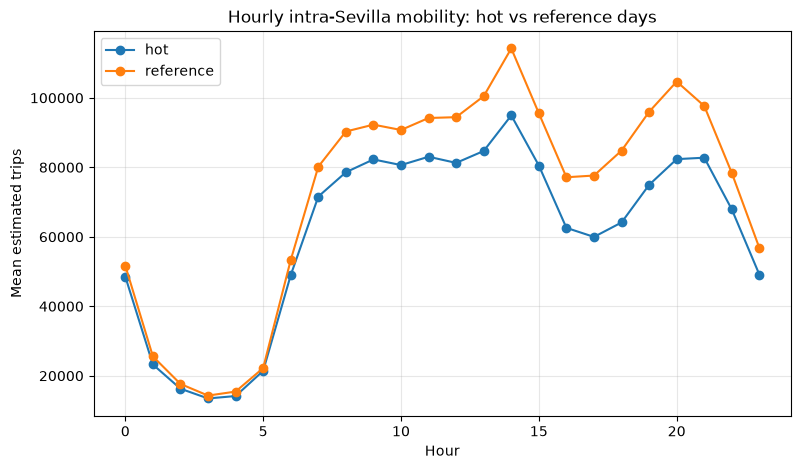

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))

for period, group in hourly_compare.groupby("thermal_period"):
    ax.plot(
        group["hour"],
        group["mean_trips"],
        marker="o",
        label=period
    )

ax.set_xlabel("Hour")
ax.set_ylabel("Mean estimated trips")
ax.set_title("Hourly intra-Sevilla mobility: hot vs reference days")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [15]:
hourly_wide = (
    hourly_compare
    .pivot(
        index="hour",
        columns="thermal_period",
        values="mean_trips"
    )
    .reset_index()
)

hourly_wide["change_pct"] = (
    (
        hourly_wide["hot"]
        - hourly_wide["reference"]
    )
    / hourly_wide["reference"]
    * 100
)

hourly_wide

thermal_period,hour,hot,reference,change_pct
0,0,48529.8944,51668.46675,-6.074445
1,1,23239.0762,25564.37175,-9.095845
2,2,16268.3680,17637.96050,-7.765028
3,3,13466.9144,14291.13450,-5.767352
4,4,14156.3230,15441.98200,-8.325738
5,5,21411.8766,22205.78850,-3.575248
6,6,48968.2916,53317.61675,-8.157389
7,7,71581.3638,80182.92700,-10.727425
8,8,78582.2198,90311.48000,-12.987563
9,9,82274.1294,92285.69700,-10.848450


In [16]:
hourly_wide[
    hourly_wide["hour"].between(12, 18)
]

thermal_period,hour,hot,reference,change_pct
12,12,81276.7594,94434.87225,-13.933532
13,13,84706.7362,100482.66800,-15.700152
14,14,94941.6232,114221.79225,-16.879589
15,15,80512.2970,95550.95100,-15.738885
16,16,62570.2746,77139.57750,-18.886936
17,17,59968.2098,77635.13875,-22.756357
18,18,64125.9920,84811.07800,-24.389604


In [17]:
afternoon_change = (
    hourly_wide.loc[
        hourly_wide["hour"].between(12, 18),
        "change_pct"
    ]
    .mean()
)

print(
    "Mean hourly mobility change, 12:00–18:00:",
    f"{afternoon_change:.1f}%"
)

Mean hourly mobility change, 12:00–18:00: -18.3%


In [18]:
def period_change(df, start, end):
    return (
        df.loc[df["hour"].between(start, end), "change_pct"]
        .mean()
    )

period_summary = pd.DataFrame({
    "period": [
        "Morning 06–11",
        "Afternoon 12–18",
        "Evening 19–23",
    ],
    "change_pct": [
        period_change(hourly_wide, 6, 11),
        period_change(hourly_wide, 12, 18),
        period_change(hourly_wide, 19, 23),
    ]
})

period_summary

,period,change_pct
0,Morning 06–11,-10.948619
1,Afternoon 12–18,-18.326436
2,Evening 19–23,-17.071757


In [19]:
district_daily = (
    intra.groupby(
        [
            "date",
            "thermal_period",
            "id_origin"
        ],
        as_index=False
    )
    .agg(
        trips=("n_trips", "sum")
    )
)

district_period = (
    district_daily.groupby(
        [
            "id_origin",
            "thermal_period"
        ],
        as_index=False
    )
    .agg(
        mean_daily_trips=("trips", "mean")
    )
)

district_wide = (
    district_period
    .pivot(
        index="id_origin",
        columns="thermal_period",
        values="mean_daily_trips"
    )
    .reset_index()
)

district_wide["change_pct"] = (
    (
        district_wide["hot"]
        - district_wide["reference"]
    )
    / district_wide["reference"]
    * 100
)

district_wide

thermal_period,id_origin,hot,reference,change_pct
0,4109101,145845.4648,178271.47150,-18.189117
1,4109102,133963.0940,153318.06200,-12.624063
2,4109103,114626.1748,140221.46800,-18.253477
3,4109104,173366.5718,192580.24175,-9.976968
4,4109105,161321.5184,199057.88275,-18.957483
5,4109106,103737.8264,123400.16850,-15.933805
6,4109107,137393.7560,157761.96925,-12.910725
7,4109108,155472.0102,181766.99075,-14.466312
8,4109109,202560.8898,231502.02550,-12.501461
9,4109110,88074.7310,106950.90175,-17.649380


In [20]:
district_wide = district_wide.merge(
    zones[
        [
            "id",
            "name",
            "population"
        ]
    ].assign(
        id=lambda x: x["id"].astype(str)
    ),
    left_on="id_origin",
    right_on="id",
    how="left"
)

district_wide[
    [
        "name",
        "reference",
        "hot",
        "change_pct"
    ]
].sort_values("change_pct")

,name,reference,hot,change_pct
4,Sevilla distrito 05,199057.88275,161321.5184,-18.957483
2,Sevilla distrito 03,140221.46800,114626.1748,-18.253477
0,Sevilla distrito 01,178271.47150,145845.4648,-18.189117
9,Sevilla distrito 10,106950.90175,88074.7310,-17.649380
10,Sevilla distrito 11,60734.93050,50959.6002,-16.095071
5,Sevilla distrito 06,123400.16850,103737.8264,-15.933805
7,Sevilla distrito 08,181766.99075,155472.0102,-14.466312
6,Sevilla distrito 07,157761.96925,137393.7560,-12.910725
1,Sevilla distrito 02,153318.06200,133963.0940,-12.624063
8,Sevilla distrito 09,231502.02550,202560.8898,-12.501461


In [25]:
district_results = (
    district_wide
    .merge(
        zones[
            [
                "id",
                "name",
                "population"
            ]
        ].assign(
            id=lambda x: x["id"].astype(str)
        ),
        left_on="id_origin",
        right_on="id",
        how="left"
    )
)
print(district_results.columns.tolist())



['id_origin', 'hot', 'reference', 'change_pct', 'id_x', 'name_x', 'population_x', 'id_y', 'name_y', 'population_y']


In [28]:
# Start only from the four columns we actually need
district_base = district_wide[
    [
        "id_origin",
        "hot",
        "reference",
        "change_pct"
    ]
].copy()

district_base["id_origin"] = district_base["id_origin"].astype(str)

# Prepare a clean district lookup
zone_lookup = zones[
    [
        "id",
        "name",
        "population"
    ]
].copy()

zone_lookup["id"] = zone_lookup["id"].astype(str)

zone_lookup = zone_lookup.rename(
    columns={
        "id": "id_origin",
        "name": "district_name",
        "population": "district_population"
    }
)

# Clean merge
district_results = district_base.merge(
    zone_lookup,
    on="id_origin",
    how="left"
)

district_results = district_results[
    [
        "id_origin",
        "district_name",
        "district_population",
        "reference",
        "hot",
        "change_pct"
    ]
].sort_values("change_pct")

district_results

,id_origin,district_name,district_population,reference,hot,change_pct
4,4109105,Sevilla distrito 05,68916.0,199057.88275,161321.5184,-18.957483
2,4109103,Sevilla distrito 03,50394.0,140221.46800,114626.1748,-18.253477
0,4109101,Sevilla distrito 01,54914.0,178271.47150,145845.4648,-18.189117
9,4109110,Sevilla distrito 10,41589.0,106950.90175,88074.7310,-17.649380
10,4109111,Sevilla distrito 11,25033.0,60734.93050,50959.6002,-16.095071
5,4109106,Sevilla distrito 06,46253.0,123400.16850,103737.8264,-15.933805
7,4109108,Sevilla distrito 08,59239.0,181766.99075,155472.0102,-14.466312
6,4109107,Sevilla distrito 07,72030.0,157761.96925,137393.7560,-12.910725
1,4109102,Sevilla distrito 02,73367.0,153318.06200,133963.0940,-12.624063
8,4109109,Sevilla distrito 09,104255.0,231502.02550,202560.8898,-12.501461


In [29]:
district_results.columns.tolist()

['id_origin',
 'district_name',
 'district_population',
 'reference',
 'hot',
 'change_pct']

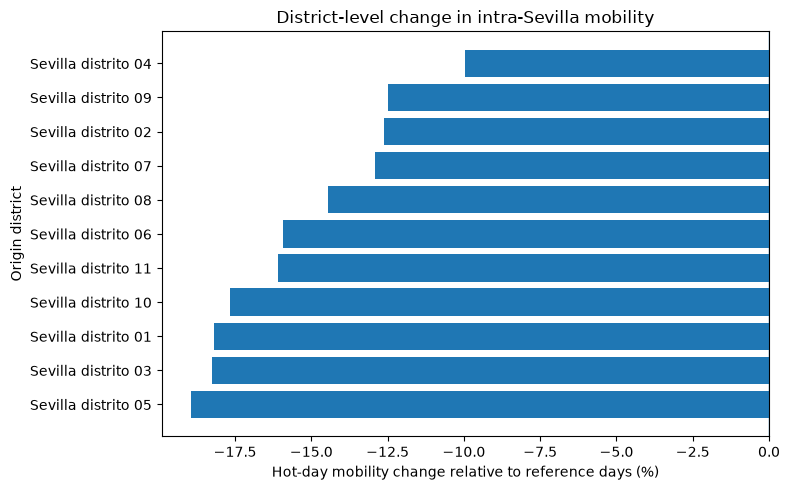

In [30]:
plot_df = district_results.sort_values("change_pct")

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    plot_df["district_name"],
    plot_df["change_pct"]
)

ax.axvline(0, linewidth=1)

ax.set_xlabel(
    "Hot-day mobility change relative to reference days (%)"
)

ax.set_ylabel("Origin district")

ax.set_title(
    "District-level change in intra-Sevilla mobility"
)

plt.tight_layout()
plt.show()

In [31]:
district_results.to_parquet(
    MOBILE_PROCESSED
    / "sevilla_district_hot_reference_mobility.parquet",
    index=False
)

## Interim findings

Across the selected matched weekdays, intra-Sevilla mobility was on average 15.7% lower on hot days than on reference days.

The reduction varied by time of day:

- Morning (06:00–11:00): -10.9%
- Afternoon (12:00–18:00): -18.3%
- Evening (19:00–23:00): -17.1%

District-level reductions ranged from roughly -10% to -19%, indicating meaningful spatial variation in the observed hot-day mobility response.

These results are descriptive and do not yet establish a causal heat effect. The next stage compares the spatial pattern of observed mobility reduction with modeled heat-conditioned accessibility loss.